<a href="https://colab.research.google.com/github/izaakrznine1/analysis-everpeak/blob/main/S9_Version_Student_Proyecto_Landing_Experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados**: Respalda tus conclusiones mediante gráficos claros.

Se aplican **puebas estadísticas apropiados** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [ ]:
# importar librerías

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportions_ztest


In [ ]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [ ]:
print(pd.__version__)


1.2.4


**Vista previa e información general del conjunto de datos**

In [ ]:
# mostrar las primeras 5 filas
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [ ]:
# información general
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


**Observaciones iniciales:**

* El conjunto de datos contiene información de usuarios expuestos a una versión de la landing page.
* Las variables incluyen información demográfica y de comportamiento como región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.
* La variable objetivo principal es converted.
* La variable gasto representa el gasto realizado por usuarios que convirtieron.
* A continuación se verificará la calidad de los datos para identificar valores faltantes, duplicados o problemas de formato.


**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [ ]:
print('Total de registros:', len(df))
print('Usuarios únicos:', df['user_id'].nunique())

print(
    'Usuarios duplicados:',
    len(df) - df['user_id'].nunique()
)

Total de registros: 40000
Usuarios únicos: 40000
Usuarios duplicados: 0


 **Variable `date`**  
Explorar rango de fechas

In [ ]:
# Resumen estadístico
df['date'] = pd.to_datetime(df['date'])

df['date'].describe()


count                   40000
unique                     28
top       2026-01-24 00:00:00
freq                     1512
first     2026-01-01 00:00:00
last      2026-01-28 00:00:00
Name: date, dtype: object

In [ ]:
# Identificar rango temporal del experimento

print("Fecha mínima:", df['date'].min())
print("Fecha máxima:", df['date'].max())


Fecha mínima: 2026-01-01 00:00:00
Fecha máxima: 2026-01-28 00:00:00


**Variable `gasto` (numérica)**

In [ ]:
# Resumen estadístico
df['gasto'].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [ ]:
# Resumen estadístico de usuarios que se convirtieron
df[df['converted'] == 1]['gasto'].describe()

count    5706.000000
mean       65.373668
std        30.896545
min        12.120000
25%        42.950000
50%        59.860000
75%        80.370000
max       303.680000
Name: gasto, dtype: float64

 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [ ]:
# Explorar variables categóricas y cómo se distribuyen
categorical_cols = [
    'landing',
    'region',
    'dispositivo',
    'traffic_source',
    'user_type',
    'converted'
]

print("\nConteo de categorías:")

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())



Conteo de categorías:

--- landing ---
B    20018
A    19982
Name: landing, dtype: int64

--- region ---
Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: region, dtype: int64

--- dispositivo ---
Mobile     24829
Desktop    15171
Name: dispositivo, dtype: int64

--- traffic_source ---
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64

--- user_type ---
Nuevo         26033
Recurrente    13967
Name: user_type, dtype: int64

--- converted ---
0    34294
1     5706
Name: converted, dtype: int64


***Hallazgos del análisis exploratorio:***

Se verificó que los 40,000 registros corresponden a usuarios únicos y no existen identificadores duplicados.

La variable date cubre el período del 01/01/2026 al 28/01/2026, con 28 fechas distintas y actividad registrada durante todo el experimento.

La variable gasto muestra una mediana de 0 y un tercer cuartil de 0 para el conjunto completo, lo que indica que la mayoría de los usuarios no realizaron una compra. Esto es consistente con la variable converted. Al analizar únicamente a los usuarios convertidos, se observó un gasto promedio de aproximadamente 65.37 unidades monetarias.

Las variables categóricas contienen únicamente categorías válidas y esperadas para el experimento. La distribución entre las versiones A y B se encuentra balanceada (19,982 y 20,018 usuarios respectivamente), lo que permite realizar comparaciones confiables.

No se identificaron valores faltantes, duplicados ni inconsistencias que requieran limpieza adicional. Por lo tanto, el conjunto de datos es adecuado para continuar con el análisis estadístico.


## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [ ]:
# Gasto por versión
gasto_A = df[(df['landing'] == 'A') & (df['converted'] == 1)]['gasto']

gasto_B = df[(df['landing'] == 'B') & (df['converted'] == 1)]['gasto']

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

### Prueba

**Hipótesis:**
- **Hipótesis nula (H₀)**: El gasto promedio de los usuarios convertidos es igual en las páginas A y B.
- **Hipótesis alternativa (H₁)**: El gasto promedio de los usuarios convertidos es diferente entre las páginas A y B.


In [ ]:
# Aplicar prueba

alpha = 0.05

results = stats.ttest_ind(
    gasto_A,
    gasto_B,
    equal_var=False
)

# Visualizar resultados

print(f"Estadístico: {results.statistic:.4f}")
print(f"Valor p: {results.pvalue:.10f}")

if results.pvalue < alpha:
    print("Rechazamos H0")
else:
    print("No rechazamos H0")


Estadístico: -9.4810
Valor p: 0.0000000000
Rechazamos H0


***Conclusión:***

Se realizó una prueba t de Student para comparar el gasto promedio de los usuarios convertidos entre las páginas A y B.

Se obtuvo un valor p prácticamente igual a cero, el cual es menor que el nivel de significancia establecido (α = 0.05). Por lo tanto, se rechaza la hipótesis nula.

Existe evidencia estadísticamente significativa para concluir que el gasto promedio de los usuarios convertidos difiere entre las versiones A y B de la landing page.

Al revisar los promedios de gasto, la página B presenta un valor promedio superior al de la página A. Esto sugiere que la versión B genera un mayor valor económico por usuario convertido y podría representar una mejor alternativa para el negocio.



---


## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen difere]ncias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):**  La tasa de conversión es igual para las páginas A y B.
- **Hipótesis alternativa (H₁):** La tasa de conversión es diferente entre las páginas A y B.

In [ ]:

# Número de usuarios convertidos por página

converted_users = df.groupby('landing')['converted'].sum()

# Total de usuarios por página

total_users = df.groupby('landing')['converted'].count()

print("Usuarios convertidos por página:\n", converted_users)

print("\nTotal de usuarios por página:\n", total_users)


Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


In [ ]:
# Aplicar prueba
alpha = 0.05

stat, p_value = proportions_ztest(
    converted_users,
    total_users
)

# Visualizar resultados

print(f"Estadístico: {stat:.4f}")
print(f"Valor p: {p_value:.10f}")

if p_value < alpha:
    print("Rechazamos H0")
else:
    print("No rechazamos H0")

Estadístico: -9.6774
Valor p: 0.0000000000
Rechazamos H0


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula, ya que el valor p es menor que 0.05.

**Interpretación de negocio:**  
Existe evidencia estadísticamente significativa para concluir que la tasa de conversión de las páginas A y B es diferente.

La página B obtuvo una mayor cantidad de usuarios convertidos y una tasa de conversión superior a la página A.

Tasa de conversión A: 2512 / 19982 = 12.57%
Tasa de conversión B: 3194 / 20018 = 15.96%

La mejora observada es de aproximadamente 3.39 puntos porcentuales, lo que indica que la página B convierte visitantes en clientes con mayor eficacia.
Desde una perspectiva de negocio, se recomienda implementar la página B, ya que genera un mayor número de conversiones y contribuye a mejorar el desempeño comercial.

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** La fuente de tráfico y la conversión son variables independientes. No existe asociación entre ellas.
- **Hipótesis alternativa (H₁):** La fuente de tráfico y la conversión no son independientes. Existe una asociación entre ellas.

In [ ]:
traffic_table = pd.crosstab(
    df['traffic_source'],
    df['converted']
)

traffic_table

converted,0,1
traffic_source,,
Ads,10176,1759
Email,5205,918
Organic,15507,2480
Referral,3406,549


In [ ]:
# Aplicar prueba

chi2, p_value, dof, expected = chi2_contingency(
    traffic_table
)

print(f"Estadístico Chi-cuadrada: {chi2:.4f}")
print(f"Valor p: {p_value:.10f}")

alpha = 0.05

if p_value < alpha:
    print("Rechazamos H0")
else:
    print("No rechazamos H0")





Estadístico Chi-cuadrada: 8.6621
Valor p: 0.0341375948
Rechazamos H0


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula (H₀), ya que el valor p (0.0341) es menor que el nivel de significancia establecido de 0.05.


**Interpretación de negocio:**  
Existe evidencia estadísticamente significativa para concluir que la fuente de tráfico y la conversión están relacionadas.

Esto indica que la probabilidad de que un usuario realice una conversión depende, al menos en parte, del canal por el que llegó al sitio web.

Al analizar la tabla de contingencia, se observa que las distintas fuentes de tráfico generan diferentes cantidades de conversiones. En particular, el tráfico orgánico aporta el mayor número absoluto de conversiones, seguido por anuncios, correo electrónico y referencias.

Desde una perspectiva de negocio, estos resultados sugieren que no todos los canales de adquisición tienen el mismo desempeño. Por lo tanto, sería recomendable analizar con mayor profundidad las tasas de conversión específicas de cada fuente para identificar cuáles generan usuarios de mayor calidad y optimizar la inversión en marketing.


## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** El tipo de usuario y la conversión son variables independientes. No existe asociación entre ellas.
- **Hipótesis alternativa (H₁):** El tipo de usuario y la conversión no son independientes. Existe una asociación entre ellas.

In [ ]:
user_table = pd.crosstab(
    df['user_type'],
    df['converted']
)

user_table

converted,0,1
user_type,,
Nuevo,22295,3738
Recurrente,11999,1968


In [ ]:
# Aplicar prueba
chi2, p_value, dof, expected = chi2_contingency(
    user_table
)

print(f"Estadístico Chi-cuadrada: {chi2:.4f}")
print(f"Valor p: {p_value:.10f}")

alpha = 0.05

if p_value < alpha:
    print("Rechazamos H0")
else:
    print("No rechazamos H0")


Estadístico Chi-cuadrada: 0.5135
Valor p: 0.4736341272
No rechazamos H0


### 📝 Conclusión e interpretación

**Decisión:**  
No se rechaza la hipótesis nula (H₀), ya que el valor p (0.4736) es mayor que el nivel de significancia de 0.05.

**Interpretación de negocio:**  
No existe evidencia estadísticamente significativa para concluir que el tipo de usuario y la conversión estén relacionados.

Los resultados sugieren que los usuarios nuevos y recurrentes presentan comportamientos de conversión similares dentro del contexto analizado.

Desde una perspectiva de negocio, el tipo de usuario no parece ser un factor determinante para explicar las conversiones observadas en este experimento. Por lo tanto, las estrategias de optimización deberían enfocarse en variables que sí demostraron una asociación significativa con la conversión, como la versión de la landing page y la fuente de tráfico.

En este conjunto de datos, la probabilidad de conversión parece ser independiente de que el usuario sea nuevo o recurrente.

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

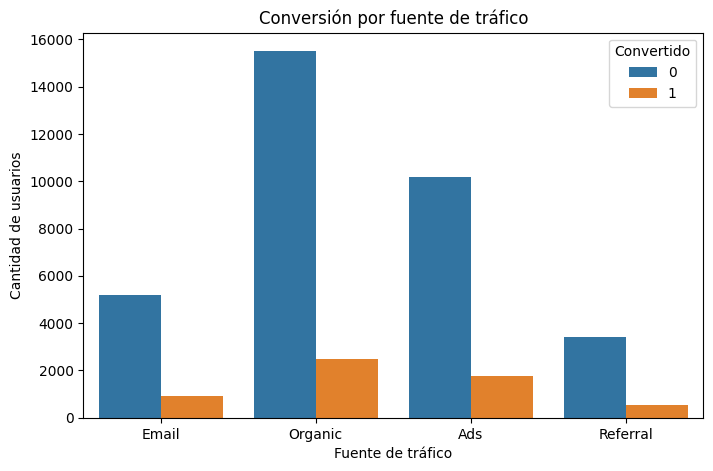

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='traffic_source',
    hue='converted'
)

plt.title('Conversión por fuente de tráfico')
plt.xlabel('Fuente de tráfico')
plt.ylabel('Cantidad de usuarios')
plt.legend(title='Convertido')

plt.show()

El gráfico muestra la cantidad de usuarios convertidos y no convertidos para cada fuente de tráfico.

El tráfico orgánico presenta el mayor volumen total de usuarios y también la mayor cantidad absoluta de conversiones. Sin embargo, el volumen por sí solo no permite determinar qué canal es más eficiente, por lo que resulta útil analizar también las proporciones de conversión.



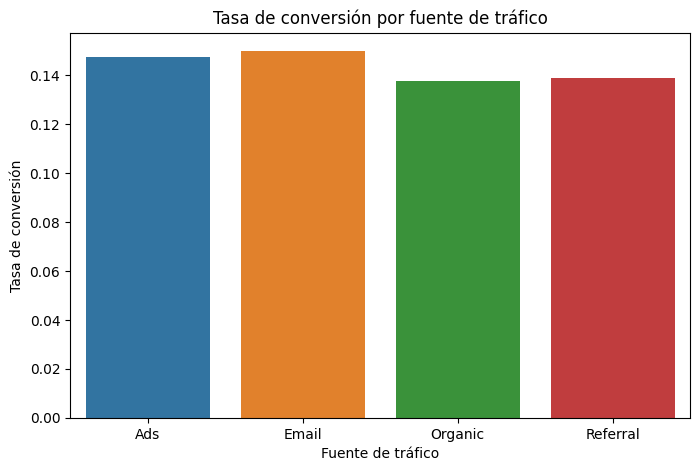

In [ ]:
conversion_rate_traffic = (
    df.groupby('traffic_source')['converted']
      .mean()
      .reset_index()
)

plt.figure(figsize=(8,5))

sns.barplot(
    data=conversion_rate_traffic,
    x='traffic_source',
    y='converted'
)

plt.title('Tasa de conversión por fuente de tráfico')
plt.xlabel('Fuente de tráfico')
plt.ylabel('Tasa de conversión')

plt.show()

El gráfico muestra la proporción de usuarios que realizaron una conversión en cada fuente de tráfico.

Se observan diferencias entre los canales, lo que coincide con los resultados de la prueba Chi-cuadrada realizada anteriormente. Esto sugiere que la fuente de tráfico puede influir en la probabilidad de conversión y que algunos canales son más efectivos para atraer usuarios con intención de compra.

### Relación entre el tipo de usuario y la conversión

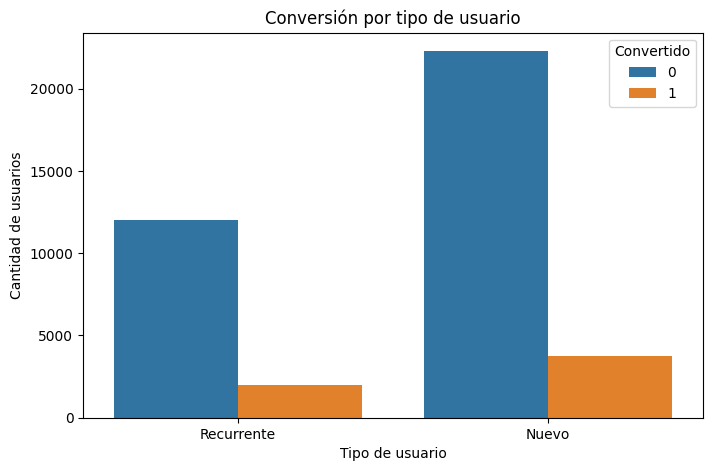

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='user_type',
    hue='converted'
)

plt.title('Conversión por tipo de usuario')
plt.xlabel('Tipo de usuario')
plt.ylabel('Cantidad de usuarios')
plt.legend(title='Convertido')

plt.show()

El gráfico presenta la cantidad de usuarios convertidos y no convertidos según el tipo de usuario.

Los usuarios nuevos representan la mayor parte de la muestra y, por lo tanto, generan el mayor número absoluto de conversiones. Sin embargo, para evaluar diferencias reales es necesario comparar las tasas de conversión.

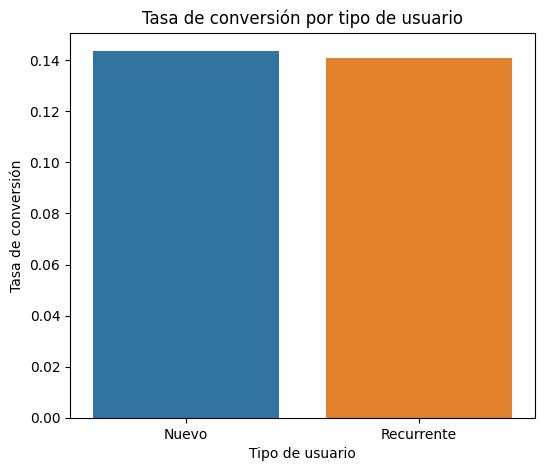

In [ ]:
conversion_rate_user = (
    df.groupby('user_type')['converted']
      .mean()
      .reset_index()
)

plt.figure(figsize=(6,5))

sns.barplot(
    data=conversion_rate_user,
    x='user_type',
    y='converted'
)

plt.title('Tasa de conversión por tipo de usuario')
plt.xlabel('Tipo de usuario')
plt.ylabel('Tasa de conversión')

plt.show()

Las tasas de conversión de usuarios nuevos y recurrentes son muy similares.

Esta observación coincide con los resultados de la prueba Chi-cuadrada, en la que no se encontró evidencia estadísticamente significativa de una relación entre el tipo de usuario y la conversión. Esto indica que, dentro de este experimento, ser un usuario nuevo o recurrente no parece influir de manera importante en la probabilidad de convertir.

## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?  
- ¿Existen diferencias significativas según el tipo de usuario?  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?


---

### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió:**
- La página A obtuvo un gasto promedio de 61.09 unidades monetarias por usuario convertido.
- La página B obtuvo un gasto promedio de 68.75 unidades monetarias por usuario convertido.
- **Interpretación:** La prueba t mostró una diferencia estadísticamente significativa (p < 0.05), por lo que la página B genera un mayor valor económico por cliente convertido.

<br>

**Tasa de conversión:**
- La página A alcanzó una tasa de conversión de 12.57% (2,512 conversiones de 19,982 usuarios).
- La página B alcanzó una tasa de conversión de 15.96% (3,194 conversiones de 20,018 usuarios).
- **Interpretación:** La diferencia es estadísticamente significativa (p < 0.05). La página B convierte visitantes en clientes de manera más efectiva que la página A.

---

#### 📊 **Segmentación por fuente de tráfico**
- Se encontró una asociación estadísticamente significativa entre la fuente de tráfico y la conversión (p = 0.034).
- El canal Organic generó el mayor número absoluto de conversiones (2,480), seguido por Ads (1,759), Email (918) y Referral (549).
- **Interpretación:** El canal de adquisición influye en la probabilidad de conversión. Algunas fuentes atraen usuarios con mayor intención de compra y deberían considerarse prioritarias en futuras estrategias de marketing.

 ---

#### 📊 **Segmentación por tipo de usuario**
- No se encontró una asociación estadísticamente significativa entre el tipo de usuario y la conversión (p = 0.474)
- Las tasas de conversión entre usuarios nuevos y recurrentes fueron similares.
- **Interpretación:** Dentro de este experimento, ser un usuario nuevo o recurrente no parece influir significativamente en la probabilidad de convertir.

---

Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores.

---

#### 💡 **Recomendaciones de negocio:**
- Implementar la página B como versión definitiva, ya que supera a la página A tanto en tasa de conversión como en gasto promedio por usuario convertido.
- Optimizar la inversión en canales de adquisición, priorizando las fuentes de tráfico con mejor desempeño en conversión.
- Continuar realizando experimentos A/B para identificar elementos específicos de la página B que impulsan las conversiones.
- Enfocar futuras segmentaciones en variables con impacto comprobado (como fuente de tráfico) y no en el tipo de usuario, ya que no mostró diferencias significativas.
- Monitorear periódicamente las métricas de conversión y gasto para validar que los resultados se mantengan una vez implementada la página B.


Los resultados del experimento muestran de forma consistente que la Landing Page B es la mejor alternativa para el negocio. Esta versión no solo genera una mayor tasa de conversión (15.96% vs 12.57%), sino también un mayor gasto promedio por cliente convertido (68.75 vs 61.09). Adicionalmente, se identificó que la fuente de tráfico influye en la conversión, mientras que el tipo de usuario no presenta un efecto significativo. Con base en estos hallazgos, se recomienda implementar la página B y orientar las estrategias de marketing hacia los canales de tráfico con mejor desempeño.